# Gyroscope-Based Activity Prediction
### Exploratory Data Analysis, Machine Learning Benchmarking & Model Interpretation

This notebook builds a reproducible machine-learning workflow for predicting the binary `is_standing` target from engineered activity-sensor features.

**Workflow**
1. Load and validate the training and testing CSV files.
2. Explore the dataset and sensor-feature distributions.
3. Prepare features and target labels.
4. Train and compare ten classification algorithms.
5. Evaluate performance using multiple metrics and diagnostic plots.
6. Interpret the best-performing model.

> **Important:** The notebook expects the existing dataset structure at `/content/activity_dataset/striker/1.Activity_Prediction/`. Change `DATA_DIR` if your files are stored elsewhere. The test files are kept separate and are used only for final evaluation.

## 1. Imports and Configuration

The libraries below cover data manipulation, visualization, preprocessing, model training, and evaluation. A fixed random seed makes randomized model operations reproducible.

In [3]:
import glob
import warnings
from pathlib import Path
import shutil
import subprocess

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report, confusion_matrix,
    ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier,
    ExtraTreesClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier

RANDOM_STATE = 42
DATA_DIR = Path("/content/activity_dataset/striker/1.Activity_Prediction")

# Download the repository and extract dataset folder
repo_url = "https://github.com/striker-sajid/gyrostepper.git"
temp_repo_dir = Path("/content/gyrostepper_temp")

print("Downloading repository from GitHub...")
if temp_repo_dir.exists():
    shutil.rmtree(temp_repo_dir)

# Clone the repository
subprocess.run(["git", "clone", repo_url, str(temp_repo_dir)], check=True)

# Ensure the destination directory exists
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Locate all CSV files anywhere in the cloned repository (such as within 'dataset' folder)
csv_files = list(temp_repo_dir.glob("**/*.csv"))

if csv_files:
    for csv_file in csv_files:
        # Copy each CSV file directly to the expected DATA_DIR
        shutil.copy(csv_file, DATA_DIR / csv_file.name)
    print(f"Successfully copied {len(csv_files)} CSV file(s) to {DATA_DIR}")
else:
    print("No CSV files found in the cloned repository.")

# Clean up the temporary repository clone directory
shutil.rmtree(temp_repo_dir)

sns.set_theme(style="whitegrid", context="notebook", palette="deep")
plt.rcParams.update({
    "figure.figsize": (10, 6),
    "axes.titlesize": 14,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "figure.dpi": 110
})

print("\nLibraries imported and dataset prepared successfully.")
print(f"Dataset directory: {DATA_DIR}")

Successfully copied 8 CSV file(s) to /content/activity_dataset/striker/1.Activity_Prediction

Libraries imported and dataset prepared successfully.
Dataset directory: /content/activity_dataset/striker/1.Activity_Prediction


## 2. Load the Training and Testing Data

The loader discovers files matching `*_train.csv` and `*_test.csv`, reads them, and combines each group. It also records the source filename for traceability; that metadata is not used as a model feature.

In [4]:
def load_csv_group(file_paths, group_name):
    if not file_paths:
        raise FileNotFoundError(
            f"No {group_name} CSV files found. Check DATA_DIR and filename patterns."
        )

    frames = []
    for file_path in file_paths:
        frame = pd.read_csv(file_path)
        frame["_source_file"] = Path(file_path).name
        frames.append(frame)

    combined = pd.concat(frames, ignore_index=True)
    print(f"{group_name}: {len(file_paths)} file(s), {combined.shape[0]:,} rows")
    return combined

train_files = sorted(DATA_DIR.glob("*_train.csv"))
test_files = sorted(DATA_DIR.glob("*_test.csv"))

df_train = load_csv_group(train_files, "Training set")
df_test = load_csv_group(test_files, "Testing set")

print("\nTraining shape:", df_train.shape)
print("Testing shape: ", df_test.shape)

display(df_train.head())

Training set: 4 file(s), 12,266 rows
Testing set: 4 file(s), 7,340 rows

Training shape: (12266, 55)
Testing shape:  (7340, 55)


,accel_x_mean,accel_x_std,accel_x_max,accel_x_min,accel_x_energy,accel_x_entropy,accel_y_mean,accel_y_std,accel_y_max,accel_y_min,...,gyro_mag_min,gyro_mag_energy,gyro_mag_entropy,extra_feature_49,extra_feature_50,extra_feature_51,extra_feature_52,label_activity,is_standing,_source_file
0,10.1693,0.1053,-0.0006,0.0006,10.1472,10.1708,10.1949,2.1359,4.0943,8.7317,...,-0.0003,0.0205,0.0447,0.0309,-0.7790,-0.5830,0.5662,standing,1,A_train.csv
1,9.5423,0.0652,-0.0001,0.0001,9.5017,9.5421,9.5904,2.5316,4.0943,8.6074,...,-0.0113,0.0336,0.0313,0.0466,0.4908,-0.9261,-0.3532,standing,1,A_train.csv
2,9.7543,0.0211,-0.0000,0.0000,9.7427,9.7556,9.7656,2.5862,4.0943,8.6493,...,-0.0008,0.0009,0.0059,0.0034,-0.3097,0.0880,-0.3327,standing,1,A_train.csv
3,9.4715,0.0251,-0.0000,0.0000,9.4583,9.4711,9.4871,2.3857,4.0943,8.5916,...,-0.0130,0.0048,0.0125,0.0303,0.4236,-0.6725,-0.1390,standing,1,A_train.csv
4,9.7295,0.0529,0.0000,0.0000,9.6860,9.7229,9.7639,2.5442,4.0943,8.6486,...,0.0031,0.0078,0.0205,0.0315,-0.2984,-0.8883,0.0231,standing,1,A_train.csv


## 3. Data Quality and Schema Validation

Before training, inspect column types, duplicate rows, missing values, and whether the training and test files have compatible schemas. The target column must be present in both datasets.

In [5]:
TARGET = "is_standing"
LABEL_COLUMN = "label_activity"

required_columns = {TARGET, LABEL_COLUMN}
for split_name, frame in [("training", df_train), ("testing", df_test)]:
    missing_required = required_columns - set(frame.columns)
    if missing_required:
        raise ValueError(f"{split_name} data is missing required columns: {missing_required}")

train_feature_columns = [
    c for c in df_train.columns if c not in {TARGET, LABEL_COLUMN, "_source_file"}
]
test_feature_columns = [
    c for c in df_test.columns if c not in {TARGET, LABEL_COLUMN, "_source_file"}
]

missing_in_test = sorted(set(train_feature_columns) - set(test_feature_columns))
extra_in_test = sorted(set(test_feature_columns) - set(train_feature_columns))
if missing_in_test or extra_in_test:
    raise ValueError(
        "Feature columns differ between train and test. "
        f"Missing in test: {missing_in_test}; extra in test: {extra_in_test}"
    )

# Keep identical feature order in both splits.
feature_columns = train_feature_columns
df_test = df_test[df_test.columns.intersection(
    [*feature_columns, TARGET, LABEL_COLUMN, "_source_file"], sort=False
)]

print(f"Number of sensor features: {len(feature_columns)}")
print("Duplicate training rows:", df_train.duplicated().sum())
print("Duplicate testing rows: ", df_test.duplicated().sum())

print("\nTraining data types:")
display(df_train[feature_columns].dtypes.value_counts().rename_axis("Data type").to_frame("Count"))

missing_summary = pd.DataFrame({
    "Missing values": df_train[feature_columns].isna().sum(),
    "Missing (%)": df_train[feature_columns].isna().mean().mul(100)
}).sort_values("Missing (%)", ascending=False)

display(missing_summary.head(15))

Number of sensor features: 52
Duplicate training rows: 6
Duplicate testing rows:  0

Training data types:


,Count
Data type,
float64,52


,Missing values,Missing (%)
accel_x_mean,0,0.0
accel_x_std,0,0.0
accel_x_max,0,0.0
accel_x_min,0,0.0
accel_x_energy,0,0.0
accel_x_entropy,0,0.0
accel_y_mean,0,0.0
accel_y_std,0,0.0
accel_y_max,0,0.0
accel_y_min,0,0.0


## 4. Exploratory Data Analysis

### 4.1 Target Distribution

Check whether the standing and non-standing classes are balanced. A strongly imbalanced target can make accuracy misleading, which is why balanced accuracy, precision, recall, and F1-score are also reported later.

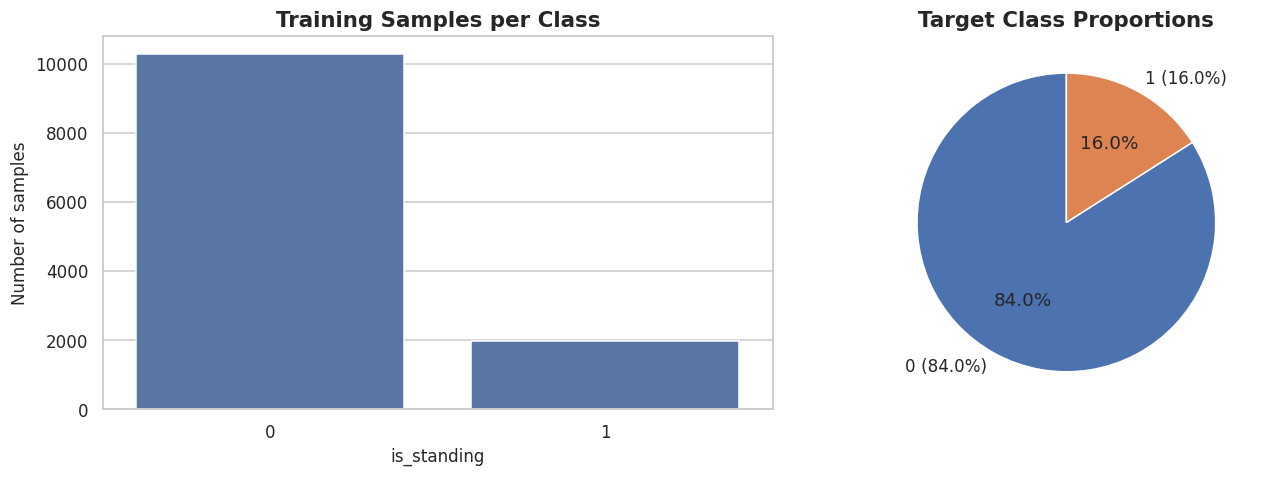

,Samples,Percentage
is_standing,,
0,10305,84.01
1,1961,15.99


In [6]:
class_counts = df_train[TARGET].value_counts(dropna=False).sort_index()
class_percent = df_train[TARGET].value_counts(normalize=True, dropna=False).sort_index() * 100

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.barplot(x=class_counts.index.astype(str), y=class_counts.values, ax=axes[0])
axes[0].set_title("Training Samples per Class")
axes[0].set_xlabel("is_standing")
axes[0].set_ylabel("Number of samples")

axes[1].pie(
    class_counts.values,
    labels=[f"{idx} ({val:.1f}%)" for idx, val in class_percent.items()],
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)
axes[1].set_title("Target Class Proportions")
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "Samples": class_counts,
    "Percentage": class_percent.round(2)
}))

### 4.2 Missing-Value Profile

The heatmap highlights features with missing observations. The table shows the exact count and percentage. Imputation is fitted on training data only later in the pipeline.

In [7]:
missing_pct = df_train[feature_columns].isna().mean().mul(100)
missing_pct = missing_pct[missing_pct > 0].sort_values(ascending=False)

if missing_pct.empty:
    print("No missing values found in the training sensor features.")
else:
    plt.figure(figsize=(11, max(4, len(missing_pct) * 0.28)))
    sns.barplot(x=missing_pct.values, y=missing_pct.index)
    plt.title("Missing Values by Sensor Feature")
    plt.xlabel("Missing values (%)")
    plt.ylabel("Feature")
    plt.tight_layout()
    plt.show()
    display(missing_summary.loc[missing_pct.index])

No missing values found in the training sensor features.


### 4.3 Sensor Feature Distributions

The histograms show the scale and shape of selected sensor features. This helps identify skew, unusual ranges, and features that may benefit from scaling.

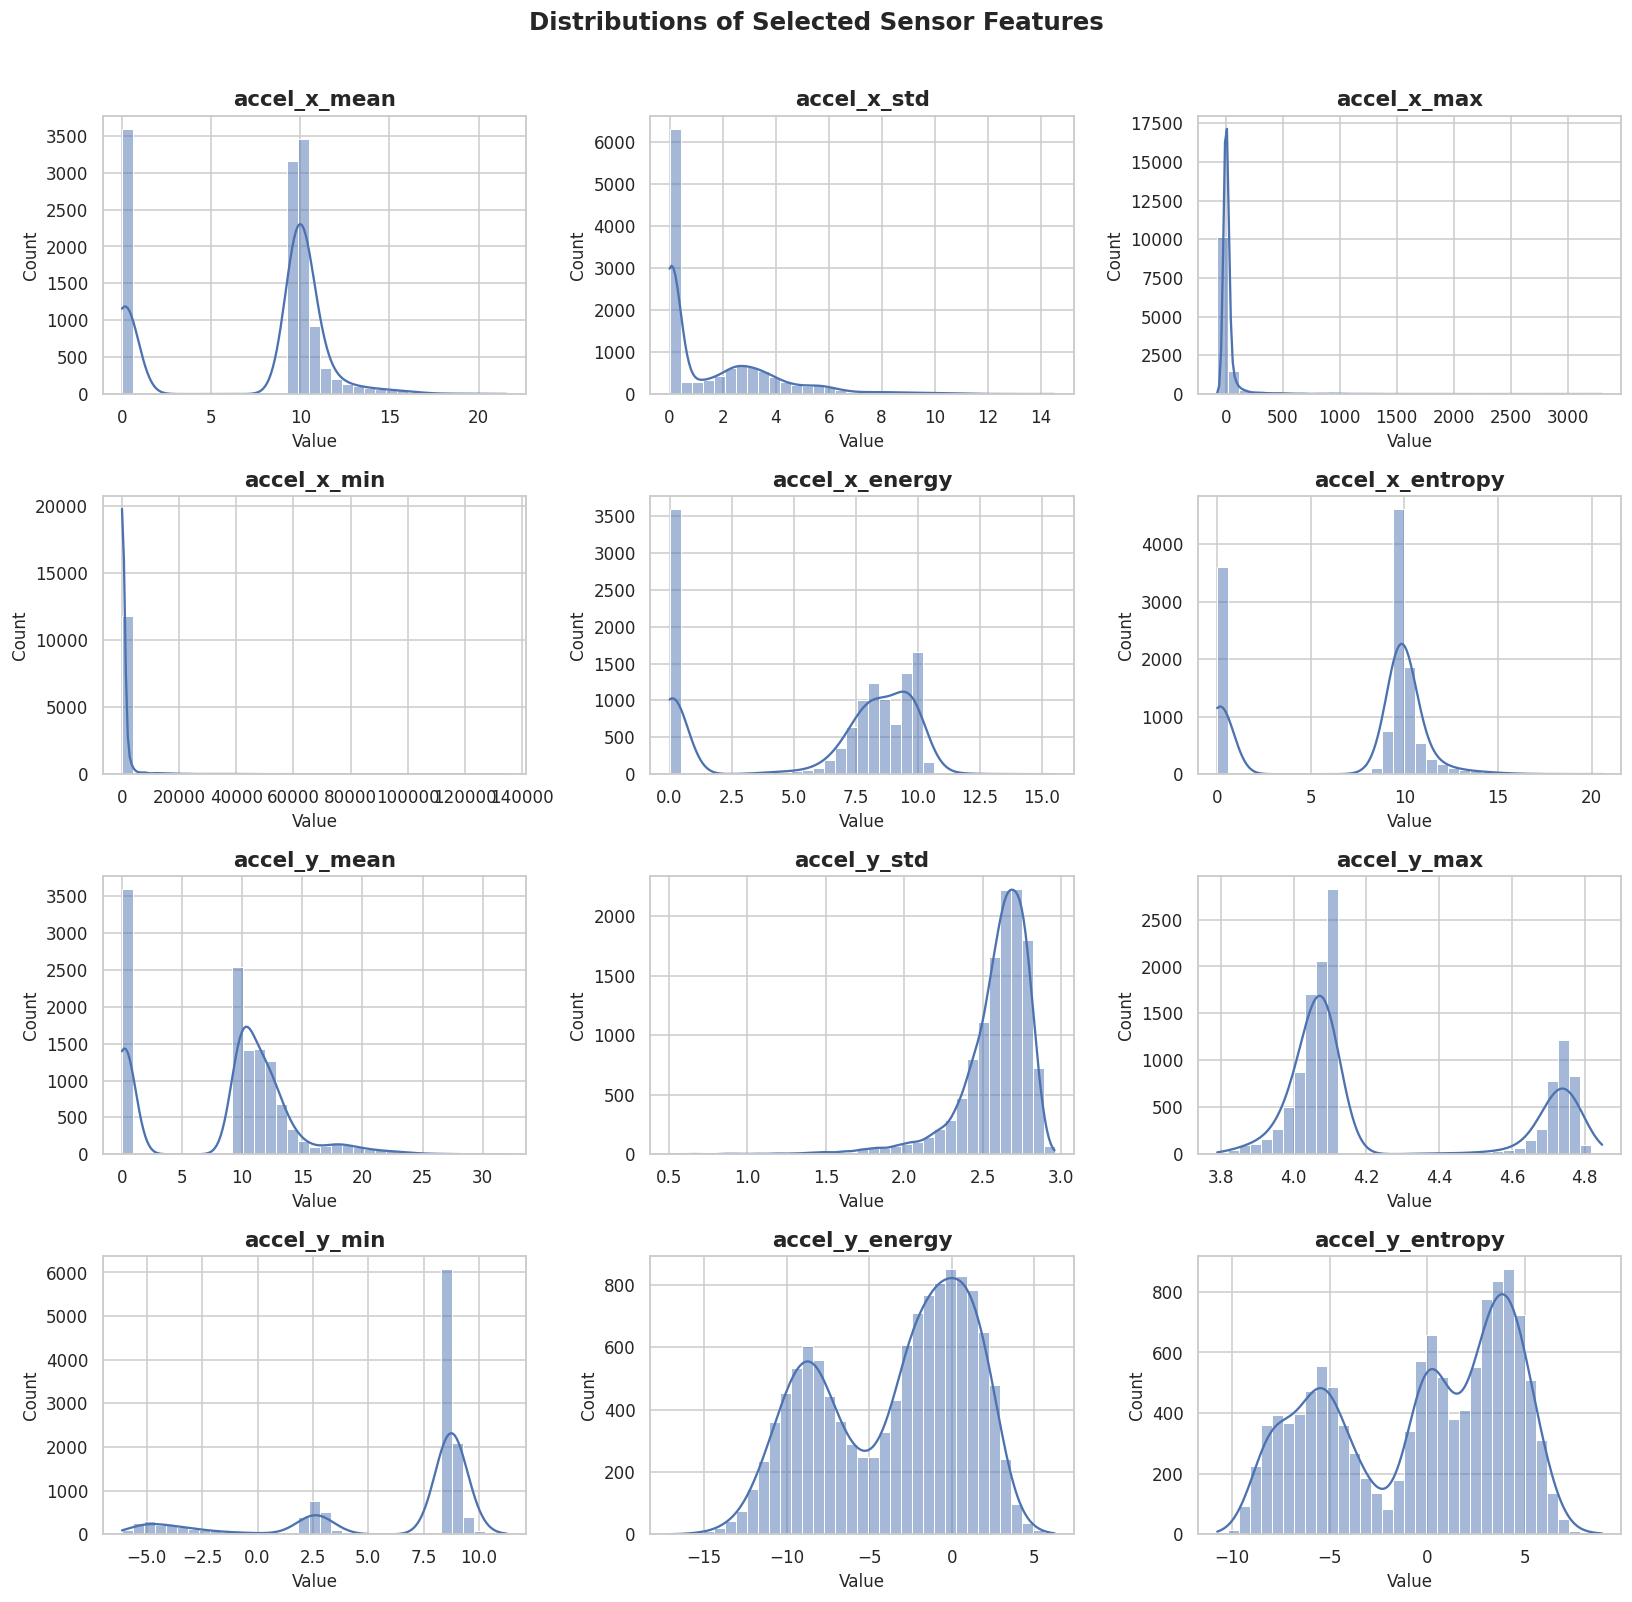

In [8]:
numeric_features = df_train[feature_columns].select_dtypes(include=np.number).columns.tolist()
if not numeric_features:
    raise ValueError("No numeric sensor features were found.")

selected_features = numeric_features[:min(12, len(numeric_features))]
n_cols = 3
n_rows = int(np.ceil(len(selected_features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 3.6 * n_rows))
axes = np.array(axes).reshape(-1)

for ax, feature in zip(axes, selected_features):
    sns.histplot(df_train[feature], bins=35, kde=True, ax=ax)
    ax.set_title(feature)
    ax.set_xlabel("Value")

for ax in axes[len(selected_features):]:
    ax.remove()

fig.suptitle("Distributions of Selected Sensor Features", y=1.01, fontsize=16, fontweight="bold")
plt.tight_layout()
plt.show()

### 4.4 Correlation Between Sensor Features

Highly correlated features may contain overlapping information. This heatmap uses the first 30 numeric features for readability; adjust `corr_features` to inspect a different subset.

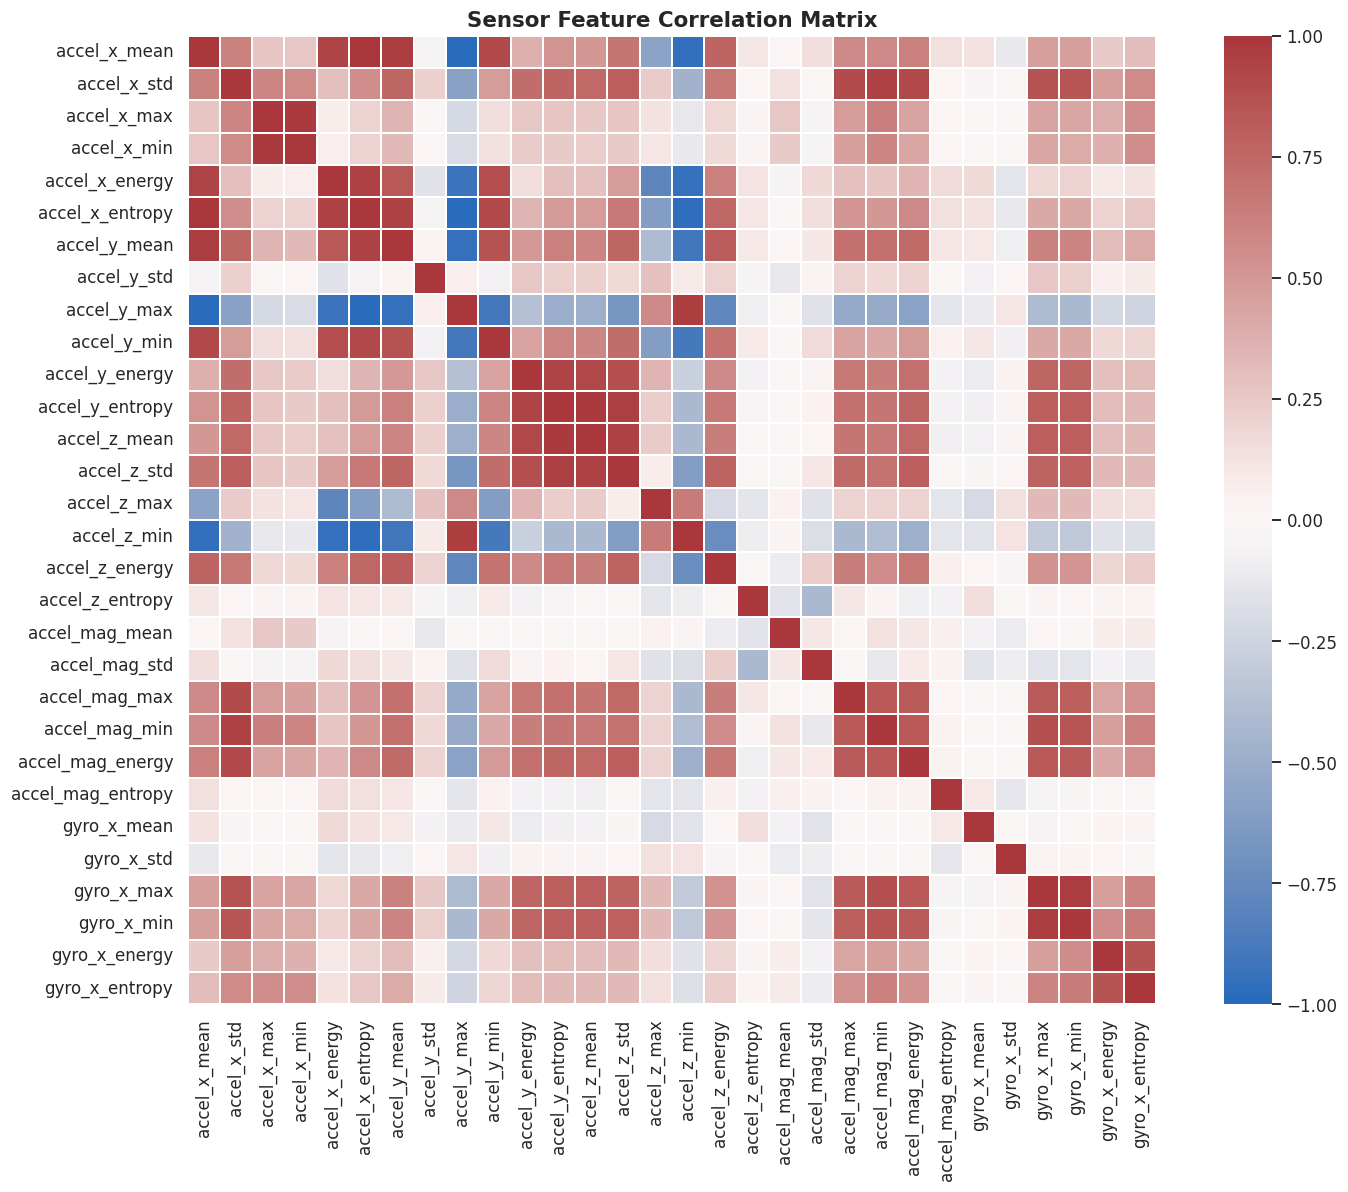

In [9]:
corr_features = numeric_features[:min(30, len(numeric_features))]
corr_matrix = df_train[corr_features].corr()

plt.figure(figsize=(14, 11))
sns.heatmap(
    corr_matrix, cmap="vlag", center=0, vmin=-1, vmax=1,
    linewidths=0.25, square=True
)
plt.title("Sensor Feature Correlation Matrix")
plt.tight_layout()
plt.show()

## 5. Prepare Features and Target

`label_activity` is descriptive text and is excluded from the model inputs. `_source_file` is tracking metadata and is also excluded. The model predicts `is_standing` using only the sensor features.

The test set remains untouched during model fitting and model selection.

In [10]:
X_train = df_train[feature_columns].copy()
X_test = df_test[feature_columns].copy()
y_train = df_train[TARGET].copy()
y_test = df_test[TARGET].copy()

if y_train.isna().any() or y_test.isna().any():
    raise ValueError("Target column contains missing values. Resolve these before training.")

# Ensure the target is consistently represented in both splits.
if set(pd.unique(y_train)) != set(pd.unique(y_test)):
    raise ValueError(
        f"Train/test target classes differ. Train={sorted(pd.unique(y_train))}; "
        f"Test={sorted(pd.unique(y_test))}"
    )

classes = sorted(pd.unique(y_train))
if len(classes) != 2:
    raise ValueError(f"This notebook's ROC/PR analysis expects a binary target; found {len(classes)} classes.")

print("Training features:", X_train.shape)
print("Testing features: ", X_test.shape)
print("Target classes:   ", classes)
print("\nTraining target distribution:")
display(y_train.value_counts().rename("Samples").to_frame())

Training features: (12266, 52)
Testing features:  (7340, 52)
Target classes:    [np.int64(0), np.int64(1)]

Training target distribution:


,Samples
is_standing,
0,10305
1,1961


## 6. Define and Train the Classifiers

Each classifier is wrapped in a scikit-learn `Pipeline`. Missing-value imputation and standardization are therefore learned from the training data within each fit, rather than from the combined train/test data.

Tree-based models do not generally require scaling, but retaining a consistent pipeline makes preprocessing reproducible and does not use test-set statistics.

In [11]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1500, random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "AdaBoost": AdaBoostClassifier(n_estimators=100, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1
    ),
    "Support Vector Machine": SVC(probability=True, random_state=RANDOM_STATE),
    "K-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "Gaussian Naive Bayes": GaussianNB(),
    "MLP Neural Network": MLPClassifier(
        hidden_layer_sizes=(100, 50), max_iter=1000,
        early_stopping=True, random_state=RANDOM_STATE
    )
}

def make_pipeline(model):
    return Pipeline(steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", clone(model))
    ])

fitted_models = {}
predictions = {}
probabilities = {}
results = []

for name, estimator in models.items():
    print(f"Training {name} ...")
    pipeline = make_pipeline(estimator)
    pipeline.fit(X_train, y_train)

    y_pred = pipeline.predict(X_test)
    fitted_models[name] = pipeline
    predictions[name] = y_pred

    # Some estimators may not expose predict_proba; all current estimators here do.
    if hasattr(pipeline, "predict_proba"):
        probabilities[name] = pipeline.predict_proba(X_test)[:, 1]
    elif hasattr(pipeline, "decision_function"):
        probabilities[name] = pipeline.decision_function(X_test)

    results.append({
        "Classifier": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, pos_label=classes[1], zero_division=0),
        "Recall": recall_score(y_test, y_pred, pos_label=classes[1], zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, pos_label=classes[1], zero_division=0),
        "ROC-AUC": (
            roc_auc_score(y_test, probabilities[name])
            if name in probabilities else np.nan
        )
    })

summary_df = pd.DataFrame(results).sort_values("F1-Score", ascending=False).reset_index(drop=True)
display(summary_df.style.format({
    "Accuracy": "{:.4f}", "Balanced Accuracy": "{:.4f}",
    "Precision": "{:.4f}", "Recall": "{:.4f}",
    "F1-Score": "{:.4f}", "ROC-AUC": "{:.4f}"
}).background_gradient(cmap="YlGn", subset=["Accuracy", "F1-Score", "ROC-AUC"]))

Training Logistic Regression ...
Training Decision Tree ...
Training Random Forest ...
Training Gradient Boosting ...
Training AdaBoost ...
Training Extra Trees ...
Training Support Vector Machine ...
Training K-Nearest Neighbors ...
Training Gaussian Naive Bayes ...
Training MLP Neural Network ...


,Classifier,Accuracy,Balanced Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest,0.9872,0.9749,0.9604,0.9570,0.9587,0.9986
1,Extra Trees,0.9866,0.9749,0.9562,0.9579,0.9571,0.9984
2,MLP Neural Network,0.9805,0.9541,0.9569,0.9158,0.9359,0.9964
3,Gradient Boosting,0.9796,0.9614,0.9335,0.9351,0.9343,0.9943
4,Decision Tree,0.9760,0.9489,0.9342,0.9096,0.9218,0.9489
5,K-Nearest Neighbors,0.9748,0.9579,0.9071,0.9333,0.9200,0.9915
6,Support Vector Machine,0.9714,0.9365,0.9266,0.8860,0.9058,0.9936
7,AdaBoost,0.9620,0.9181,0.8960,0.8544,0.8747,0.9900
8,Logistic Regression,0.9346,0.8661,0.8033,0.7667,0.7846,0.9722
9,Gaussian Naive Bayes,0.8264,0.8797,0.4711,0.9570,0.6314,0.8951


## 7. Compare Model Performance

### 7.1 Multi-Metric Model Comparison

Accuracy alone can hide poor performance on a minority class. This chart compares accuracy, balanced accuracy, precision, recall, F1-score, and ROC-AUC on the held-out test set.

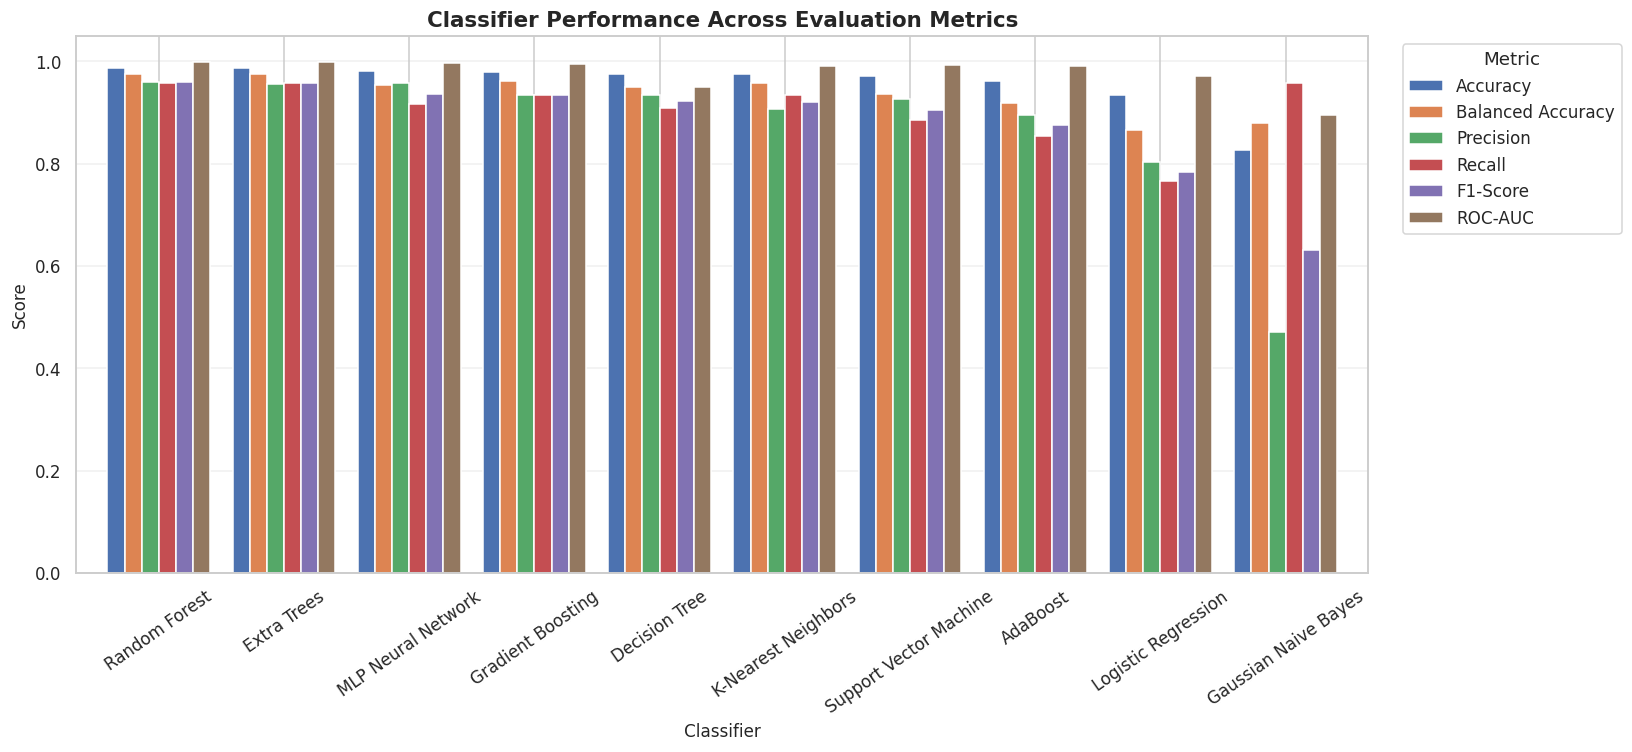

In [12]:
metric_columns = ["Accuracy", "Balanced Accuracy", "Precision", "Recall", "F1-Score", "ROC-AUC"]
plot_metrics = summary_df.set_index("Classifier")[metric_columns]

ax = plot_metrics.plot(kind="bar", figsize=(15, 7), width=0.82)
ax.set_title("Classifier Performance Across Evaluation Metrics")
ax.set_xlabel("Classifier")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=35)
ax.legend(title="Metric", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### 7.2 Ranked F1-Score and Accuracy

F1-score is the harmonic mean of precision and recall. It is useful when both false positives and false negatives matter. Review the other metrics as well before choosing a model.

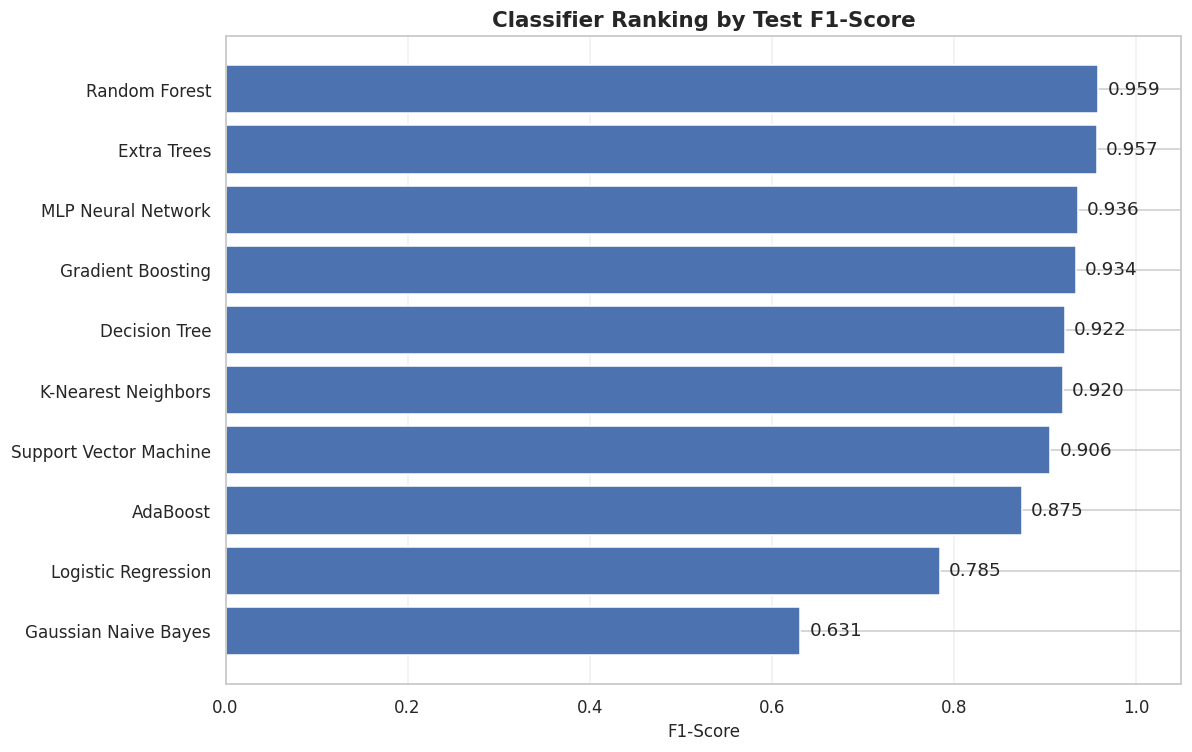

In [13]:
ranked = summary_df.sort_values("F1-Score", ascending=True)

fig, ax = plt.subplots(figsize=(11, 7))
bars = ax.barh(ranked["Classifier"], ranked["F1-Score"])
ax.set_xlim(0, 1.05)
ax.set_xlabel("F1-Score")
ax.set_title("Classifier Ranking by Test F1-Score")
ax.grid(axis="x", alpha=0.3)

for bar, score in zip(bars, ranked["F1-Score"]):
    ax.text(score + 0.01, bar.get_y() + bar.get_height()/2, f"{score:.3f}", va="center")

plt.tight_layout()
plt.show()

## 8. Detailed Evaluation of the Best Model

The best model below is selected by test F1-score for convenient inspection. For a final unbiased estimate in a research setting, model selection should be performed using training-only cross-validation, with the test set evaluated once after selection.

Selected model: Random Forest

Classification report:
              precision    recall  f1-score   support

           0       0.99      0.99      0.99      6200
           1       0.96      0.96      0.96      1140

    accuracy                           0.99      7340
   macro avg       0.98      0.97      0.98      7340
weighted avg       0.99      0.99      0.99      7340



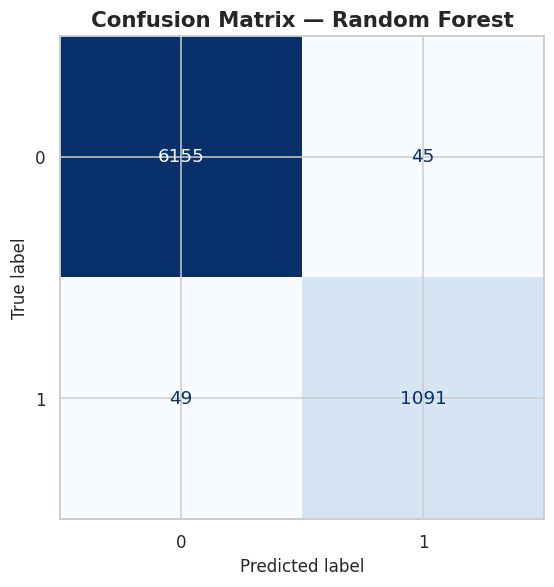

In [14]:
best_name = summary_df.loc[0, "Classifier"]
best_model = fitted_models[best_name]
best_predictions = predictions[best_name]

print("Selected model:", best_name)
print("\nClassification report:")
print(classification_report(y_test, best_predictions, zero_division=0))

cm = confusion_matrix(y_test, best_predictions, labels=classes)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=classes)
fig, ax = plt.subplots(figsize=(6.5, 5.5))
disp.plot(cmap="Blues", values_format="d", ax=ax, colorbar=False)
ax.set_title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

## 9. ROC and Precision-Recall Curves

ROC curves show the trade-off between true-positive and false-positive rates across thresholds. Precision-recall curves are particularly informative when class proportions are uneven.

The positive class is the second class in the sorted target labels (`classes[1]`).

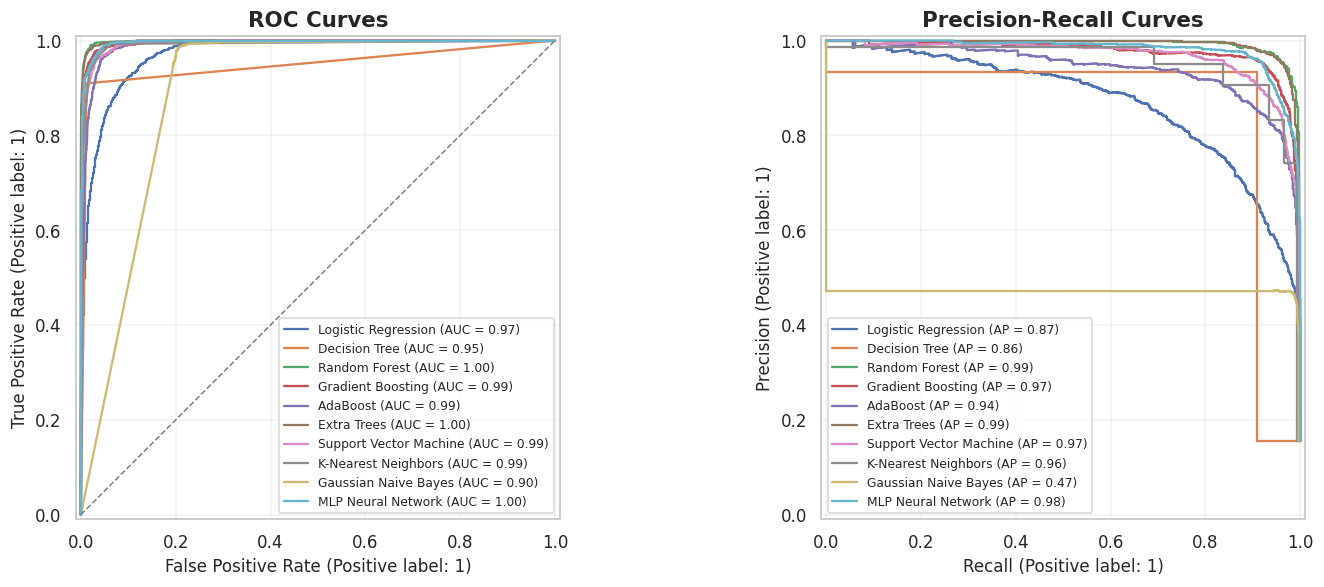

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

for name, score_values in probabilities.items():
    RocCurveDisplay.from_predictions(
        y_test, score_values, pos_label=classes[1], name=name, ax=axes[0]
    )
    PrecisionRecallDisplay.from_predictions(
        y_test, score_values, pos_label=classes[1], name=name, ax=axes[1]
    )

axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", linewidth=1)
axes[0].set_title("ROC Curves")
axes[1].set_title("Precision-Recall Curves")
axes[0].grid(alpha=0.25)
axes[1].grid(alpha=0.25)
axes[0].legend(fontsize=8, loc="lower right")
axes[1].legend(fontsize=8, loc="best")
plt.tight_layout()
plt.show()

## 10. Model Interpretation: Sensor Feature Importance

For tree-based classifiers, built-in feature importance provides a quick indication of which inputs contributed most to the fitted model's splits. This is a model-specific measure, not proof of causality.

The section uses the best model if it is a tree ensemble or decision tree. If another model wins, Random Forest is used as an interpretable reference model for this section.

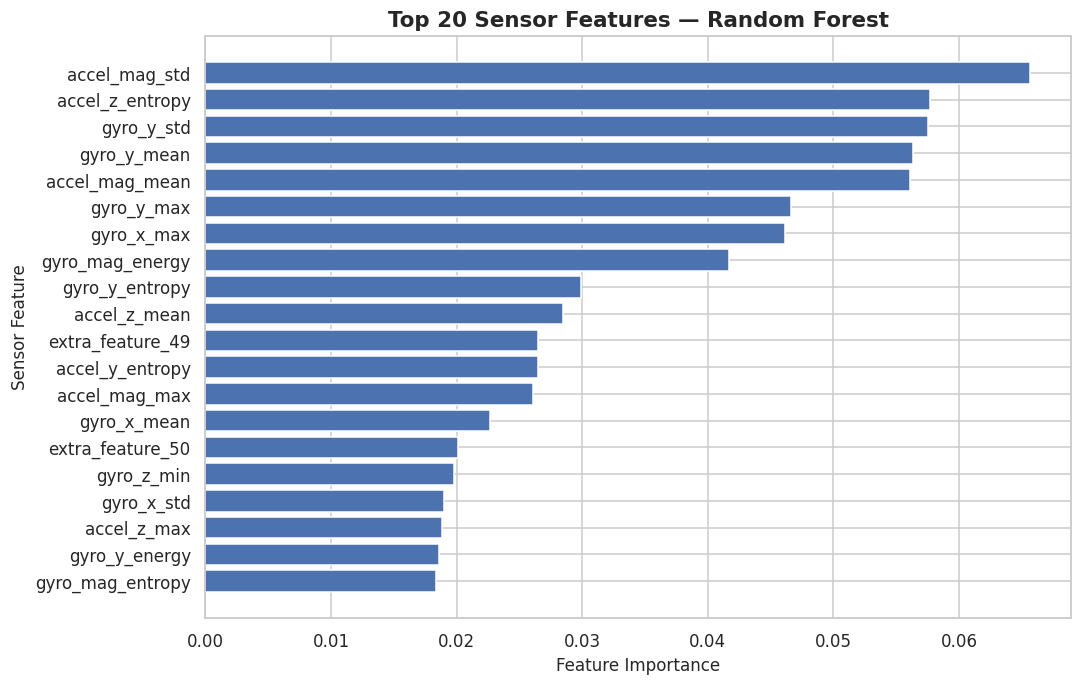

,Importance
accel_mag_std,0.065658
accel_z_entropy,0.057658
gyro_y_std,0.057539
gyro_y_mean,0.056365
accel_mag_mean,0.056061
gyro_y_max,0.046633
gyro_x_max,0.046177
gyro_mag_energy,0.041721
gyro_y_entropy,0.029869
accel_z_mean,0.028460


In [16]:
tree_candidates = {
    "Decision Tree", "Random Forest", "Gradient Boosting",
    "AdaBoost", "Extra Trees"
}
importance_name = best_name if best_name in tree_candidates else "Random Forest"
importance_pipeline = fitted_models[importance_name]
importance_estimator = importance_pipeline.named_steps["classifier"]

if hasattr(importance_estimator, "feature_importances_"):
    importance = pd.Series(
        importance_estimator.feature_importances_,
        index=feature_columns
    ).sort_values(ascending=False)

    top_n = min(20, len(importance))
    top_importance = importance.head(top_n).sort_values()

    fig, ax = plt.subplots(figsize=(10, max(6, top_n * 0.32)))
    ax.barh(top_importance.index, top_importance.values)
    ax.set_title(f"Top {top_n} Sensor Features — {importance_name}")
    ax.set_xlabel("Feature Importance")
    ax.set_ylabel("Sensor Feature")
    plt.tight_layout()
    plt.show()

    display(importance.head(top_n).rename("Importance").to_frame())
else:
    print(f"{importance_name} does not expose built-in feature_importances_.")

## 11. Optional: Cross-Validation on the Training Set

Cross-validation provides a more stable estimate of model performance using only the training split. It does not replace the held-out test evaluation. This cell can take additional time, especially for SVM, KNN, and the neural network.

If the smallest class has fewer than five examples, reduce `n_splits`.

In [17]:
minimum_class_count = int(y_train.value_counts().min())
n_splits = min(5, minimum_class_count)

if n_splits < 2:
    print("Not enough samples in the smallest class for stratified cross-validation.")
else:
    cv = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=RANDOM_STATE)
    scoring = {
        "accuracy": "accuracy",
        "balanced_accuracy": "balanced_accuracy",
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "roc_auc": "roc_auc"
    }

    cv_rows = []
    for name, estimator in models.items():
        print(f"Cross-validating {name} ...")
        scores = cross_validate(
            make_pipeline(estimator), X_train, y_train,
            cv=cv, scoring=scoring, n_jobs=-1,
            error_score="raise"
        )
        row = {"Classifier": name}
        for metric in scoring:
            row[f"{metric}_mean"] = scores[f"test_{metric}"].mean()
            row[f"{metric}_std"] = scores[f"test_{metric}"].std()
        cv_rows.append(row)

    cv_summary = pd.DataFrame(cv_rows).sort_values("f1_mean", ascending=False)
    display(cv_summary.style.format(precision=4))

Cross-validating Logistic Regression ...
Cross-validating Decision Tree ...
Cross-validating Random Forest ...
Cross-validating Gradient Boosting ...
Cross-validating AdaBoost ...
Cross-validating Extra Trees ...
Cross-validating Support Vector Machine ...
Cross-validating K-Nearest Neighbors ...
Cross-validating Gaussian Naive Bayes ...
Cross-validating MLP Neural Network ...


,Classifier,accuracy_mean,accuracy_std,balanced_accuracy_mean,balanced_accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std,roc_auc_mean,roc_auc_std
2,Random Forest,0.9804,0.0015,0.9543,0.0044,0.9599,0.0040,0.9159,0.0090,0.9373,0.0050,0.9972,0.0004
5,Extra Trees,0.9783,0.0032,0.9505,0.0081,0.9525,0.0074,0.9097,0.0154,0.9306,0.0106,0.9970,0.0005
3,Gradient Boosting,0.9701,0.0035,0.9384,0.0052,0.9188,0.0165,0.8919,0.0090,0.9051,0.0106,0.9930,0.0007
9,MLP Neural Network,0.9630,0.0038,0.9264,0.0079,0.8936,0.0136,0.8725,0.0148,0.8828,0.0120,0.9917,0.0009
1,Decision Tree,0.9622,0.0014,0.9304,0.0067,0.8803,0.0082,0.8837,0.0151,0.8819,0.0053,0.9304,0.0067
7,K-Nearest Neighbors,0.9571,0.0024,0.9284,0.0070,0.8516,0.0080,0.8863,0.0144,0.8685,0.0081,0.9815,0.0030
6,Support Vector Machine,0.9548,0.0021,0.9040,0.0043,0.8815,0.0124,0.8292,0.0094,0.8544,0.0065,0.9858,0.0010
4,AdaBoost,0.9509,0.0047,0.8979,0.0154,0.8663,0.0157,0.8200,0.0321,0.8421,0.0175,0.9864,0.0020
0,Logistic Regression,0.9171,0.0032,0.8214,0.0069,0.7741,0.0180,0.6808,0.0156,0.7242,0.0093,0.9591,0.0038
8,Gaussian Naive Bayes,0.7943,0.0046,0.8693,0.0032,0.4363,0.0056,0.9796,0.0058,0.6037,0.0053,0.8756,0.0031


## 12. Final Findings and Interpretation

Use the results generated above to write the final conclusions. Avoid claiming that one model is universally best: performance depends on the dataset, class balance, split strategy, and evaluation metric.

**Suggested points to discuss**
- Which classifier achieved the strongest test F1-score and ROC-AUC?
- Did accuracy and balanced accuracy tell the same story?
- Which class produced more false positives or false negatives?
- Which sensor features ranked highest in the tree-based importance analysis?
- Did cross-validation support the ranking seen on the held-out test set?
- What limitations remain (for example, participant overlap, sensor placement, class imbalance, or distribution shift)?

> **Methodological note:** If multiple CSV files represent different people or recording sessions, verify that the train/test split is participant- or session-independent. Random row-level splitting can overestimate real-world performance when highly related sensor windows appear in both splits.